In [1]:
!pip install stim pymatching

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.9/625.9 kB 20.6 MB/s eta 0:00:00


n=1: done
n=3: done
n=5: done
n=7: done
Saved plot to part1_classical_repetition.png


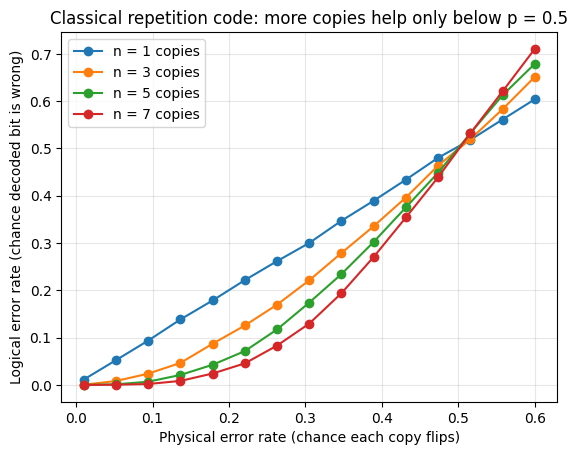

In [2]:
"""
Part 1: Classical repetition code (no quantum needed).

Idea: to protect one bit, copy it n times. Noise flips each copy with
probability p. Decode by majority vote. If fewer than half the copies
flip, we recover the original bit.

Question we answer: when does adding more copies actually help?
"""
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)  # fixed seed so results are repeatable


def encode(bit, n):
    """Copy one bit n times, e.g. 1 -> [1, 1, 1]."""
    return np.full(n, bit)


def add_noise(codeword, p):
    """Flip each bit independently with probability p."""
    flips = rng.random(codeword.size) < p
    return codeword ^ flips


def decode(received):
    """Majority vote: return 1 if more than half the bits are 1."""
    return int(received.sum() > received.size / 2)


def logical_error_rate(n, p, trials=20_000):
    """Fraction of trials where the decoded bit is wrong."""
    errors = 0
    for _ in range(trials):
        bit = rng.integers(2)
        if decode(add_noise(encode(bit, n), p)) != bit:
            errors += 1
    return errors / trials


if __name__ == "__main__":
    physical_rates = np.linspace(0.01, 0.6, 15)
    code_sizes = [1, 3, 5, 7]  # n=1 means "no protection"

    for n in code_sizes:
        rates = [logical_error_rate(n, p) for p in physical_rates]
        plt.plot(physical_rates, rates, marker="o", label=f"n = {n} copies")
        print(f"n={n}: done")

    plt.xlabel("Physical error rate (chance each copy flips)")
    plt.ylabel("Logical error rate (chance decoded bit is wrong)")
    plt.title("Classical repetition code: more copies help only below p = 0.5")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig("part1_classical_repetition.png", dpi=150, bbox_inches="tight")
    print("Saved plot to part1_classical_repetition.png")

distance 3: 0.0044, 0.0068, 0.0123, 0.0205, 0.0322, 0.0502, 0.0792, 0.1233
distance 5: 0.0019, 0.0046, 0.0095, 0.0183, 0.0370, 0.0701, 0.1300, 0.2167
distance 7: 0.0007, 0.0017, 0.0049, 0.0152, 0.0366, 0.0874, 0.1829, 0.3080


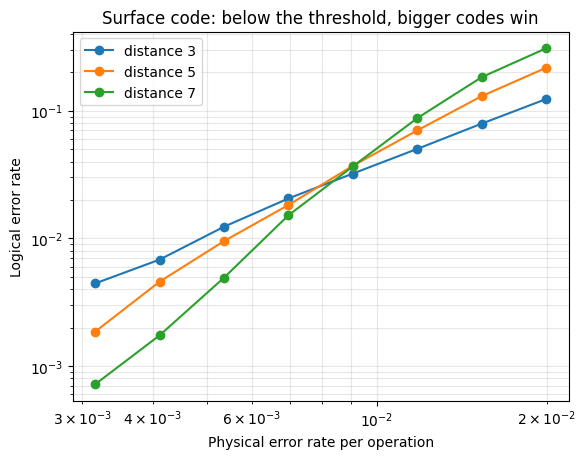

In [3]:
"""
Part 2: Quantum surface code, simulated with Stim and decoded with PyMatching.

Stim builds a noisy quantum error-correction circuit and samples
"syndromes" (the error-detection signals). PyMatching is the decoder:
it reads the syndromes and guesses which errors happened, using
minimum-weight perfect matching.

Question we answer: is there a physical error rate (the "threshold")
below which making the code bigger makes the logical qubit MORE reliable?
"""
import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching


def logical_error_rate(distance, p, shots=50_000):
    """Simulate a rotated surface code memory experiment and decode it."""
    circuit = stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=distance,
        rounds=distance,                      # repeat error-checks d times
        after_clifford_depolarization=p,      # noise after each gate
        before_measure_flip_probability=p,    # noisy measurements
        after_reset_flip_probability=p,       # noisy resets
    )

    # Sample: what the detectors saw, and whether the logical qubit actually flipped
    sampler = circuit.compile_detector_sampler()
    detections, actual_flips = sampler.sample(shots, separate_observables=True)

    # Build the decoder from the circuit's error model
    error_model = circuit.detector_error_model(decompose_errors=True)
    decoder = pymatching.Matching.from_detector_error_model(error_model)

    predicted_flips = decoder.decode_batch(detections)
    mistakes = np.any(predicted_flips != actual_flips, axis=1).sum()
    return mistakes / shots


physical_rates = np.logspace(-2.5, -1.7, 8)  # from about 0.3% to 2%
distances = [3, 5, 7]                         # code size (bigger = more qubits)

for d in distances:
    rates = [logical_error_rate(d, p) for p in physical_rates]
    plt.loglog(physical_rates, rates, marker="o", label=f"distance {d}")
    print(f"distance {d}: " + ", ".join(f"{r:.4f}" for r in rates))

plt.xlabel("Physical error rate per operation")
plt.ylabel("Logical error rate")
plt.title("Surface code: below the threshold, bigger codes win")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.savefig("part2_surface_code_threshold.png", dpi=150, bbox_inches="tight")
plt.show()